# Step 3: Grounding Accuracy Benchmark

**Topic:** Measuring click-grounding accuracy of the Step 2 vision model against known ground-truth targets

**Resources used:**
- ScreenSpot methodology (point-in-bounding-box correctness, not raw pixel distance) for GUI grounding evaluation
- Step 2 (`02-screenshot-agent-loop/screenshot_agent_loop.ipynb`) for the screenshot capture and Groq vision call pattern
- Groq vision docs (console.groq.com/docs/vision), same `qwen/qwen3.8-27b` model as Step 2 for consistency

**Summary:** Builds a local test window with known-coordinate targets varying in size and type (text-labeled vs icon-like), asks the vision model to locate each one, scores hits by point-in-bbox, and reports accuracy split by category.


## Setup

Run this cell first. Requires `GROQ_API_KEY` in a `.env` file in the working directory, same as Step 2.

In [1]:
!pip install mss groq python-dotenv pandas matplotlib


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import time
import json
import base64
import random
import tkinter as tk

import mss
import mss.tools
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from groq import Groq

load_dotenv()
client = Groq(api_key=os.environ["GROQ_API_KEY"])

VISION_MODEL = "qwen/qwen3.8-27b"  # same model as Step 2, keeps results comparable


## Section 1: Build a test window with known ground-truth targets

A real app window is used instead of just drawing shapes in an image, because the
benchmark needs to test the model against an actual screenshot of the actual screen,
matching how Step 2's loop sees things. Buttons are placed on a fixed grid (not fully
random) so targets can't overlap, ground truth comes from `winfo_rootx/rooty`, the
absolute screen position tkinter itself reports, not a value we guess.

In [3]:
# Icon-like targets use a single symbol and no descriptive text, mimicking icon-only
# UI buttons where a model can't just read a label to find the target
ICON_SYMBOLS = ["\u2699", "\u2605", "\u2702", "\u26A0", "\u2764"]  # gear, star, scissors, warning, heart
TEXT_LABELS = ["Submit", "Cancel", "Settings", "Profile", "Search"]

LARGE_SIZE = (120, 50)
SMALL_SIZE = (30, 30)

def build_test_window(n_per_category=2, seed=42):
    random.seed(seed)
    root = tk.Tk()
    root.title("Grounding accuracy test targets")
    root.geometry("900x600+100+100")  # fixed position and size, so layout is reproducible

    targets = []
    target_id = 0

    categories = [
        ("text_large", True, LARGE_SIZE, TEXT_LABELS),
        ("text_small", True, SMALL_SIZE, TEXT_LABELS),
        ("icon_large", False, LARGE_SIZE, ICON_SYMBOLS),
        ("icon_small", False, SMALL_SIZE, ICON_SYMBOLS),
    ]

    # simple grid layout, one row per category, columns spaced out to avoid overlap
    for row, (category, is_text, size, pool) in enumerate(categories):
        for col in range(n_per_category):
            width, height = size
            content = random.choice(pool)
            x = 60 + col * 200
            y = 60 + row * 130

            btn = tk.Button(root, text=content, width=1, height=1)
            btn.place(x=x, y=y, width=width, height=height)

            target_id += 1
            targets.append({
                "id": target_id,
                "category": category,
                "size_class": "large" if size == LARGE_SIZE else "small",
                "is_icon": not is_text,
                "content": content,
                "widget": btn,
            })

    root.update()  # forces geometry to be computed so winfo_* below is accurate

    # fill in absolute screen coordinates now that the window is actually rendered
    for t in targets:
        w = t["widget"]
        x1 = w.winfo_rootx()
        y1 = w.winfo_rooty()
        x2 = x1 + w.winfo_width()
        y2 = y1 + w.winfo_height()
        t["bbox"] = (x1, y1, x2, y2)
        t["center"] = ((x1 + x2) // 2, (y1 + y2) // 2)
        del t["widget"]  # not JSON-serializable, and not needed after bbox is captured

    return root, targets


Test this section on its own, a window should appear with 8 buttons and stay open.

In [4]:
test_root, test_targets = build_test_window()
for t in test_targets:
    print(t)


{'id': 1, 'category': 'text_large', 'size_class': 'large', 'is_icon': False, 'content': 'Submit', 'bbox': (168, 191, 288, 241), 'center': (228, 216)}
{'id': 2, 'category': 'text_large', 'size_class': 'large', 'is_icon': False, 'content': 'Submit', 'bbox': (368, 191, 488, 241), 'center': (428, 216)}
{'id': 3, 'category': 'text_small', 'size_class': 'small', 'is_icon': False, 'content': 'Settings', 'bbox': (168, 321, 198, 351), 'center': (183, 336)}
{'id': 4, 'category': 'text_small', 'size_class': 'small', 'is_icon': False, 'content': 'Cancel', 'bbox': (368, 321, 398, 351), 'center': (383, 336)}
{'id': 5, 'category': 'icon_large', 'size_class': 'large', 'is_icon': True, 'content': '★', 'bbox': (168, 451, 288, 501), 'center': (228, 476)}
{'id': 6, 'category': 'icon_large', 'size_class': 'large', 'is_icon': True, 'content': '★', 'bbox': (368, 451, 488, 501), 'center': (428, 476)}
{'id': 7, 'category': 'icon_small', 'size_class': 'small', 'is_icon': True, 'content': '⚙', 'bbox': (168, 581,

## Section 2: Screenshot and ask the model to locate one target

One query per target, each with a referring expression (label text or icon description)
rather than coordinates, since giving coordinates in the prompt would defeat the point
of testing grounding. `keep_running=True` on the tkinter window is handled by calling
`root.update()` before each screenshot, so the window stays responsive without a
blocking `mainloop()` call.

In [5]:
ICON_NAMES = {
    "\u2699": "gear icon",
    "\u2605": "star icon",
    "\u2702": "scissors icon",
    "\u26A0": "warning triangle icon",
    "\u2764": "heart icon",
}

def capture_screenshot_base64():
    with mss.mss() as sct:
        monitor = sct.monitors[1]
        shot = sct.grab(monitor)
        png_bytes = mss.tools.to_png(shot.rgb, shot.size)
    return base64.b64encode(png_bytes).decode("utf-8")


def build_referring_expression(target):
    if target["is_icon"]:
        return f"the small button showing a {ICON_NAMES.get(target['content'], 'symbol')}"
    return f"the button labeled '{target['content']}'"


def ask_model_to_locate(base64_image, referring_expression):
    prompt = (
        f"Find {referring_expression} in this screenshot. "
        "Respond with ONLY a JSON object in this exact shape: "
        '{"x": <int>, "y": <int>}, giving the pixel coordinates of the center '
        "of that element. No other text."
    )

    response = client.chat.completions.create(
        model=VISION_MODEL,
        messages=[
            {
                "role": "user",
                "content": [
                    {"type": "text", "text": prompt},
                    {
                        "type": "image_url",
                        "image_url": {"url": f"data:image/png;base64,{base64_image}"},
                    },
                ],
            }
        ],
        response_format={"type": "json_object"},
        temperature=0.2,
        max_completion_tokens=100,
    )
    return response.choices[0].message.content


Test on a single target before running the full benchmark.

In [6]:
test_root.update()  # make sure the window is drawn and on top before screenshotting
b64_image = capture_screenshot_base64()

sample_target = test_targets[0]
expr = build_referring_expression(sample_target)
raw = ask_model_to_locate(b64_image, expr)
print("Referring expression:", expr)
print("Ground truth bbox:", sample_target["bbox"])
print("Model response:", raw)


C:\Users\zaras\AppData\Local\Temp\ipykernel_1920\1570702068.py:10: DeprecationWarning: mss.mss is deprecated and will be removed in a future release; use mss.MSS instead
  with mss.mss() as sct:


Referring expression: the button labeled 'Submit'
Ground truth bbox: (168, 191, 288, 241)
Model response: {"x": 1019, "y": 115}


## Section 3: Score a prediction

A hit is the predicted point falling inside the ground-truth bounding box, this is the
ScreenSpot-style metric. A prediction that lands a few pixels outside a small icon still
counts as a miss even if it is visually close, because in a real agent loop that miss is
a click on the wrong element.

In [7]:
def parse_point(raw_response):
    try:
        data = json.loads(raw_response)
        return int(data["x"]), int(data["y"])
    except (json.JSONDecodeError, KeyError, TypeError, ValueError):
        return None, None


def point_in_bbox(px, py, bbox):
    if px is None or py is None:
        return False
    x1, y1, x2, y2 = bbox
    return x1 <= px <= x2 and y1 <= py <= y2


In [8]:
px, py = parse_point(raw)
hit = point_in_bbox(px, py, sample_target["bbox"])
print(f"Predicted point: ({px}, {py}), hit: {hit}")


Predicted point: (1019, 115), hit: False


## Section 4: Run the full benchmark

Runs all targets from the same window instance so ground truth stays consistent across
the whole run. `time.sleep` between queries is not for animation, it just avoids hammering
the API back to back.

In [9]:
def run_benchmark(root, targets, delay_between_queries=0.5):
    root.update()
    results = []

    for target in targets:
        b64_image = capture_screenshot_base64()
        expr = build_referring_expression(target)
        raw = ask_model_to_locate(b64_image, expr)
        px, py = parse_point(raw)
        hit = point_in_bbox(px, py, target["bbox"])

        cx, cy = target["center"]
        offset_x = None if px is None else px - cx
        offset_y = None if py is None else py - cy

        results.append({
            "id": target["id"],
            "category": target["category"],
            "size_class": target["size_class"],
            "is_icon": target["is_icon"],
            "content": target["content"],
            "bbox": target["bbox"],
            "pred_x": px,
            "pred_y": py,
            "hit": hit,
            "offset_x": offset_x,
            "offset_y": offset_y,
        })

        time.sleep(delay_between_queries)

    return pd.DataFrame(results)


In [10]:
benchmark_df = run_benchmark(test_root, test_targets)
benchmark_df


C:\Users\zaras\AppData\Local\Temp\ipykernel_1920\1570702068.py:10: DeprecationWarning: mss.mss is deprecated and will be removed in a future release; use mss.MSS instead
  with mss.mss() as sct:


,id,category,size_class,is_icon,content,bbox,pred_x,pred_y,hit,offset_x,offset_y
0,1,text_large,large,False,Submit,"(168, 191, 288, 241)",62,136,False,-166,-80
1,2,text_large,large,False,Submit,"(368, 191, 488, 241)",22,118,False,-406,-98
2,3,text_small,small,False,Settings,"(168, 321, 198, 351)",22,847,False,-161,511
3,4,text_small,small,False,Cancel,"(368, 321, 398, 351)",607,541,False,224,205
4,5,icon_large,large,True,★,"(168, 451, 288, 501)",931,48,False,703,-428
5,6,icon_large,large,True,★,"(368, 451, 488, 501)",931,48,False,503,-428
6,7,icon_small,small,True,⚙,"(168, 581, 198, 611)",20,836,False,-163,240
7,8,icon_small,small,True,❤,"(368, 581, 398, 611)",889,461,False,506,-135


## Section 5: Accuracy by category, table and chart

Grouping by category (not just an overall accuracy number) is the point, an overall hit
rate hides whether failures cluster on small icons, which is the known weak spot for
grounding models.

In [11]:
accuracy_by_category = benchmark_df.groupby("category")["hit"].mean().sort_values()
accuracy_by_size = benchmark_df.groupby("size_class")["hit"].mean().sort_values()
accuracy_by_type = benchmark_df.groupby("is_icon")["hit"].mean().rename(index={True: "icon", False: "text"})

print("Hit rate by category:")
print(accuracy_by_category)
print("\nHit rate by size class:")
print(accuracy_by_size)
print("\nHit rate by target type:")
print(accuracy_by_type)


Hit rate by category:
category
icon_large    0.0
icon_small    0.0
text_large    0.0
text_small    0.0
Name: hit, dtype: float64

Hit rate by size class:
size_class
large    0.0
small    0.0
Name: hit, dtype: float64

Hit rate by target type:
is_icon
text    0.0
icon    0.0
Name: hit, dtype: float64


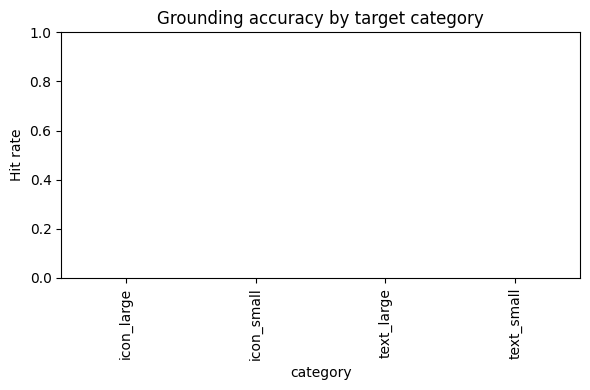

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
accuracy_by_category.plot(kind="bar", ax=ax)
ax.set_ylabel("Hit rate")
ax.set_ylim(0, 1)
ax.set_title("Grounding accuracy by target category")
plt.tight_layout()
plt.show()


## Failure mode inspection

This lists actual misses from your run with their offset direction, so you can see if
errors cluster in one direction (systematic bias) or scatter randomly (noise). Fill in
the written observations below after reading the printed misses, this can't be written
in advance since it depends on your actual run's results.

In [13]:
misses = benchmark_df[~benchmark_df["hit"]]
print(f"{len(misses)} of {len(benchmark_df)} targets missed\n")
for _, row in misses.iterrows():
    print(
        f"id={row['id']} category={row['category']} content={row['content']!r} "
        f"bbox={row['bbox']} predicted=({row['pred_x']}, {row['pred_y']}) "
        f"offset=({row['offset_x']}, {row['offset_y']})"
    )


8 of 8 targets missed

id=1 category=text_large content='Submit' bbox=(168, 191, 288, 241) predicted=(62, 136) offset=(-166, -80)
id=2 category=text_large content='Submit' bbox=(368, 191, 488, 241) predicted=(22, 118) offset=(-406, -98)
id=3 category=text_small content='Settings' bbox=(168, 321, 198, 351) predicted=(22, 847) offset=(-161, 511)
id=4 category=text_small content='Cancel' bbox=(368, 321, 398, 351) predicted=(607, 541) offset=(224, 205)
id=5 category=icon_large content='★' bbox=(168, 451, 288, 501) predicted=(931, 48) offset=(703, -428)
id=6 category=icon_large content='★' bbox=(368, 451, 488, 501) predicted=(931, 48) offset=(503, -428)
id=7 category=icon_small content='⚙' bbox=(168, 581, 198, 611) predicted=(20, 836) offset=(-163, 240)
id=8 category=icon_small content='❤' bbox=(368, 581, 398, 611) predicted=(889, 461) offset=(506, -135)


**Observed failure modes (fill in after running the cell above):**

- Which category had the lowest hit rate?
- Do the misses share an offset direction (e.g. consistently predicting a few pixels
  left or above the true center), suggesting a systematic bias, or do they scatter with
  no shared direction?
- For icon misses specifically, does the model appear to be confusing similar-looking
  symbols, or missing them by a large margin (indicating it didn't locate the region at
  all)?


In [14]:
test_root.destroy()  # close the test window once you're done inspecting results


## Section 6: Compare against DOM-based vs vision-based grounding (Phase 6 Step 3)

`vision_grounding.ipynb` in `browser-agent-from-scratch` compared DOM-based and
vision-based element location on automationexercise.com, but that notebook did not
export its results to a file this notebook can load. If you have exported results from
that run, point `PHASE6_RESULTS_PATH` at the file and this cell will load and compare
them. Otherwise this stays a manual follow-up, this notebook's numbers should not be
compared against unlogged results from memory.

In [15]:
PHASE6_RESULTS_PATH = "../browser-agent-from-scratch/03-vision-grounding/results.json"  # adjust if needed

if os.path.exists(PHASE6_RESULTS_PATH):
    with open(PHASE6_RESULTS_PATH) as f:
        phase6_results = json.load(f)
    print("Loaded Phase 6 Step 3 results for comparison:")
    print(phase6_results)
else:
    print(
        f"No results file found at {PHASE6_RESULTS_PATH}. "
        "Manual follow-up: open vision_grounding.ipynb, note its vision-based accuracy, "
        "and compare it against accuracy_by_category above by hand."
    )


No results file found at ../browser-agent-from-scratch/03-vision-grounding/results.json. Manual follow-up: open vision_grounding.ipynb, note its vision-based accuracy, and compare it against accuracy_by_category above by hand.
